# Leicester City 2015/16: análisis de una temporada histórica

## 1. Introducción

La temporada 2015/16 de la Premier League tuvo como protagonista a Leicester City, que ganó el título en una de las campañas más sorprendentes de la historia del fútbol.

El objetivo de este análisis es responder una pregunta: **¿cómo logró Leicester City ganar la Premier League 2015/16?**

Para responderla, el notebook aborda estas preguntas:

1. ¿Qué tan regular fue su rendimiento? (sección 3)
2. ¿Cómo se compara con el resto de la liga en puntos, goles a favor y goles en contra? (sección 4)
3. ¿Dependió de jugar como local? (sección 5)
4. ¿Fue más eficiente que sus rivales de cara al arco? (sección 6)
5. ¿Superó las expectativas de las casas de apuestas? (sección 7)
6. ¿Cómo se construyó el título a lo largo de la temporada? (sección 8)

En la sección 2 se cargan, validan y preparan los datos, y en la sección 9 se reúnen las conclusiones.

## 2. Preparación y validación de los datos

Cargamos el dataset y definimos las constantes del proyecto.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA_PATH = "../data/season-1516_csv.csv"
IMAGES_DIR = Path("../images")
TEAM = "Leicester"

df = pd.read_csv(DATA_PATH)

df.head()

,Div,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,HTHG,HTAG,HTR,...,BbAv<2.5,BbAH,BbAHh,BbMxAHH,BbAvAHH,BbMxAHA,BbAvAHA,PSCH,PSCD,PSCA
0,E0,08/08/15,Bournemouth,Aston Villa,0,1,A,0,0,D,...,1.79,26,-0.5,1.98,1.93,1.99,1.92,1.82,3.88,4.70
1,E0,08/08/15,Chelsea,Swansea,2,2,D,2,1,H,...,1.99,27,-1.5,2.24,2.16,1.80,1.73,1.37,5.04,10.88
2,E0,08/08/15,Everton,Watford,2,2,D,0,1,A,...,1.96,26,-1.0,2.28,2.18,1.76,1.71,1.75,3.76,5.44
3,E0,08/08/15,Leicester,Sunderland,4,2,H,3,0,H,...,1.67,26,-0.5,2.00,1.95,1.96,1.90,1.79,3.74,5.10
4,E0,08/08/15,Man United,Tottenham,1,0,H,1,0,H,...,2.01,26,-1.0,2.20,2.09,1.82,1.78,1.64,4.07,6.04


Estilo de los gráficos: Leicester se destaca en azul y el resto de los equipos en gris, para que el foco esté siempre en el equipo analizado.

In [2]:
HIGHLIGHT = "#2a78d6"       # Leicester
NEUTRAL = "#bdbbb5"         # resto de los equipos
REFERENCE = "#8f8d87"       # líneas de referencia
TEXT_PRIMARY = "#0b0b0b"
TEXT_SECONDARY = "#52514e"

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlecolor": TEXT_PRIMARY,
    "axes.labelcolor": TEXT_SECONDARY,
    "axes.edgecolor": "#c9c7c1",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "grid.color": "#e6e5e1",
    "grid.linewidth": 0.8,
    "savefig.dpi": 150,
    "savefig.bbox": "tight"
})

IMAGES_DIR.mkdir(exist_ok=True)

Renombramos las columnas con nombres descriptivos

In [3]:
column_names = {
    "Div": "division",
    "Date": "match_date",
    "HomeTeam": "home_team",
    "AwayTeam": "away_team",
    "FTHG": "home_goals",
    "FTAG": "away_goals",
    "FTR": "full_time_result",
    "HTHG": "home_half_time_goals",
    "HTAG": "away_half_time_goals",
    "HTR": "half_time_result",
    "Referee": "referee",
    "HS": "home_shots",
    "AS": "away_shots",
    "HST": "home_shots_on_target",
    "AST": "away_shots_on_target",
    "HF": "home_fouls",
    "AF": "away_fouls",
    "HC": "home_corners",
    "AC": "away_corners",
    "HY": "home_yellow_cards",
    "AY": "away_yellow_cards",
    "HR": "home_red_cards",
    "AR": "away_red_cards"
}

df = df.rename(columns=column_names)

Convertimos `match_date` de texto a fecha.

Hasta ahora la fecha se conservaba como texto (formato dd/mm/yy). Para analizar la evolución de la temporada necesitamos ordenar los partidos cronológicamente, y eso requiere que Pandas interprete la columna como fecha. Se indica el formato explícitamente para evitar que un día se interprete como mes.

In [4]:
df["match_date"] = pd.to_datetime(df["match_date"], format="%d/%m/%y")

print("Fechas nulas:", df["match_date"].isna().sum())
print("Primera fecha:", df["match_date"].min().date())
print("Última fecha:", df["match_date"].max().date())

Fechas nulas: 0
Primera fecha: 2015-08-08
Última fecha: 2016-05-17


### Exploración inicial

Dimensiones del dataset y tipos de datos de sus columnas.

In [5]:
print("Filas y columnas:", df.shape)
print()
print(df.dtypes.value_counts().to_string())

Filas y columnas: (380, 65)

float64           39
int64             19
object             6
datetime64[ns]     1


### Valores nulos

In [6]:
df.isnull().sum().sort_values(ascending=False)

BWA           1
BWD           1
BWH           1
division      0
match_date    0
             ..
BbMxAHA       0
BbAvAHA       0
PSCH          0
PSCD          0
PSCA          0
Length: 65, dtype: int64

Filas con valores nulos

In [7]:
df[df[["BWH", "BWD", "BWA"]].isnull().any(axis=1)]

,division,match_date,home_team,away_team,home_goals,away_goals,full_time_result,home_half_time_goals,away_half_time_goals,half_time_result,...,BbAv<2.5,BbAH,BbAHh,BbMxAHH,BbAvAHH,BbMxAHA,BbAvAHA,PSCH,PSCD,PSCA
158,E0,2015-12-13,Tottenham,Newcastle,1,2,A,1,0,H,...,2.35,30,-1.5,2.1,2.03,1.88,1.83,1.37,5.54,9.01


Se identificaron tres valores nulos en las columnas BWH, BWD y BWA, correspondientes a las cuotas de Betway para el partido Tottenham vs. Newcastle del 13/12/2015.

Se decidió conservar el registro. Las cuotas de Betway no se usan en este análisis (las cuotas utilizadas son las de Bet365), por lo que estos valores faltantes no afectan ningún cálculo.

### Registros duplicados

In [8]:
print("Filas duplicadas:", df.duplicated().sum())

Filas duplicadas: 0


### Coherencia entre goles y resultados

In [9]:
df["full_time_result"].value_counts(dropna=False)

full_time_result
H    157
A    116
D    107
Name: count, dtype: int64

Buscamos partidos donde los goles no coinciden con el resultado registrado

In [10]:
df[
    (
        (df["home_goals"] > df["away_goals"]) &
        (df["full_time_result"] != "H")
    ) |
    (
        (df["home_goals"] < df["away_goals"]) &
        (df["full_time_result"] != "A")
    ) |
    (
        (df["home_goals"] == df["away_goals"]) &
        (df["full_time_result"] != "D")
    )
]

,division,match_date,home_team,away_team,home_goals,away_goals,full_time_result,home_half_time_goals,away_half_time_goals,half_time_result,...,BbAv<2.5,BbAH,BbAHh,BbMxAHH,BbAvAHH,BbMxAHA,BbAvAHA,PSCH,PSCD,PSCA


Se verificó que los resultados finales de los 380 partidos coincidan con los goles registrados. No se encontraron inconsistencias entre los goles del equipo local, los del visitante y el resultado final (H, A o D).

### Valores negativos

In [11]:
stat_columns = [
    "home_goals",
    "away_goals",
    "home_half_time_goals",
    "away_half_time_goals",
    "home_shots",
    "away_shots",
    "home_shots_on_target",
    "away_shots_on_target",
    "home_fouls",
    "away_fouls",
    "home_corners",
    "away_corners",
    "home_yellow_cards",
    "away_yellow_cards",
    "home_red_cards",
    "away_red_cards"
]

(df[stat_columns] < 0).sum()

home_goals              0
away_goals              0
home_half_time_goals    0
away_half_time_goals    0
home_shots              0
away_shots              0
home_shots_on_target    0
away_shots_on_target    0
home_fouls              0
away_fouls              0
home_corners            0
away_corners            0
home_yellow_cards       0
away_yellow_cards       0
home_red_cards          0
away_red_cards          0
dtype: int64

Se revisaron las columnas relacionadas con las estadísticas de los partidos, incluyendo goles, tiros, tiros al arco, faltas, córners y tarjetas. No se encontraron valores negativos en ninguna de las variables analizadas.

Por lo tanto, no fue necesario realizar modificaciones en los datos.

### Coherencia entre tiros y tiros al arco

In [12]:
# Los tiros al arco nunca pueden superar a los tiros totales
df[
    (df["home_shots_on_target"] > df["home_shots"]) |
    (df["away_shots_on_target"] > df["away_shots"])
][[
    "match_date",
    "home_team",
    "away_team",
    "home_shots",
    "home_shots_on_target",
    "away_shots",
    "away_shots_on_target"
]]


,match_date,home_team,away_team,home_shots,home_shots_on_target,away_shots,away_shots_on_target
170,2015-12-26,Aston Villa,West Ham,5,8,10,4


Se encontró una inconsistencia: en el partido Aston Villa vs. West Ham del 26/12/2015, Aston Villa registra 5 tiros totales y 8 tiros al arco, algo imposible.

Se decidió conservar el registro sin modificarlo, porque el dataset no permite saber cuál de los dos valores es el incorrecto y cualquier corrección sería una suposición.

Impacto en el análisis:

- No afecta a Leicester ni a la comparación con los equipos del 2° al 5° puesto.
- Sí entra en el gráfico de tiros contra goles de la sección 6, que incluye a los 20 equipos. Si el error está en los tiros totales, Aston Villa tendría al menos 3 tiros más de los 368 registrados en la temporada; si está en los tiros al arco, los tiros totales no cambian. El valor real no se puede conocer, pero Aston Villa es el equipo con menos tiros y menos goles de la liga, en el extremo inferior del gráfico, por lo que una diferencia de pocos tiros no cambia su posición ni la lectura del gráfico.

### Selección de columnas

Seleccionamos las columnas relevantes para el análisis. Incluimos las cuotas de Bet365 de victoria local (B365H), empate (B365D) y victoria visitante (B365A), que se usan en la sección de apuestas.

In [13]:
df_analysis = df[
    [
        "match_date",
        "home_team",
        "away_team",
        "home_goals",
        "away_goals",
        "home_shots",
        "away_shots",
        "home_shots_on_target",
        "away_shots_on_target",
        "B365H",
        "B365D",
        "B365A"
    ]
]

### Formato largo: una fila por equipo por partido

El dataset original tiene una fila por partido, con columnas separadas para el local (`home_*`) y el visitante (`away_*`). Como todas las preguntas del análisis son por equipo, convertimos cada partido en dos filas: una desde el punto de vista del local y otra desde el visitante. Así, cualquier métrica por equipo se calcula con un `groupby`, sin repetir la lógica de "si es local tomo una columna, si es visitante tomo la otra".

In [14]:
home_columns = {
    "home_team": "team",
    "away_team": "opponent",
    "home_goals": "goals_for",
    "away_goals": "goals_against",
    "home_shots": "shots",
    "home_shots_on_target": "shots_on_target",
    "B365H": "odds",
    "B365D": "draw_odds",
    "B365A": "opponent_odds"
}

away_columns = {
    "away_team": "team",
    "home_team": "opponent",
    "away_goals": "goals_for",
    "home_goals": "goals_against",
    "away_shots": "shots",
    "away_shots_on_target": "shots_on_target",
    "B365A": "odds",
    "B365D": "draw_odds",
    "B365H": "opponent_odds"
}

long_columns = [
    "match_date",
    "team",
    "opponent",
    "venue",
    "goals_for",
    "goals_against",
    "shots",
    "shots_on_target",
    "odds",
    "draw_odds",
    "opponent_odds"
]

home = df_analysis.rename(columns=home_columns).assign(venue="home")[long_columns]
away = df_analysis.rename(columns=away_columns).assign(venue="away")[long_columns]

team_matches = pd.concat([home, away], ignore_index=True)

team_matches.head()

,match_date,team,opponent,venue,goals_for,goals_against,shots,shots_on_target,odds,draw_odds,opponent_odds
0,2015-08-08,Bournemouth,Aston Villa,home,0,1,11,2,2.00,3.6,4.00
1,2015-08-08,Chelsea,Swansea,home,2,2,11,3,1.36,5.0,11.00
2,2015-08-08,Everton,Watford,home,2,2,10,5,1.70,3.9,5.50
3,2015-08-08,Leicester,Sunderland,home,4,2,19,8,1.95,3.5,4.33
4,2015-08-08,Man United,Tottenham,home,1,0,9,1,1.65,4.0,6.00


El resultado se calcula a partir de los goles. En la sección de validaciones se comprobó que los goles coinciden con `full_time_result` en los 380 partidos, por lo que ambos enfoques son equivalentes.

In [15]:
# Resultado y puntos desde el punto de vista de cada equipo
team_matches["result"] = np.select(
    [
        team_matches["goals_for"] > team_matches["goals_against"],
        team_matches["goals_for"] == team_matches["goals_against"]
    ],
    ["Win", "Draw"],
    default="Loss"
)

team_matches["points"] = team_matches["result"].map({"Win": 3, "Draw": 1, "Loss": 0})

# Validación: 380 partidos x 2 equipos = 760 filas, y 38 partidos por equipo
print("Filas:", len(team_matches))
print("Partidos por equipo:", team_matches["team"].value_counts().unique())

Filas: 760
Partidos por equipo: [38]


Ordenamos los partidos cronológicamente y numeramos los partidos de cada equipo del 1 al 38. Esto permite seguir la evolución de cada equipo a lo largo de la temporada.

In [16]:
team_matches = team_matches.sort_values("match_date", kind="stable").reset_index(drop=True)
team_matches["match_number"] = team_matches.groupby("team").cumcount() + 1

Calculamos los puntos que esperaba el mercado en cada partido, a partir de las cuotas de Bet365:

1. La probabilidad implícita de un resultado es 1 / cuota. Por ejemplo, una cuota de 2.00 equivale a un 50%.
2. Las probabilidades de victoria, empate y derrota suman un poco más de 100%, porque la casa de apuestas incluye su margen de ganancia. Las dividimos por su suma para que sumen exactamente 100%.
3. Los puntos esperados de un partido son 3 × P(victoria) + 1 × P(empate).

Estas columnas se usan en la sección 7.

In [17]:
implied_win = 1 / team_matches["odds"]
implied_draw = 1 / team_matches["draw_odds"]
implied_loss = 1 / team_matches["opponent_odds"]
total = implied_win + implied_draw + implied_loss

team_matches["win_probability"] = implied_win / total
team_matches["draw_probability"] = implied_draw / total
team_matches["expected_points"] = 3 * team_matches["win_probability"] + team_matches["draw_probability"]

print("Margen promedio de la casa de apuestas:", round((total.mean() - 1) * 100, 2), "%")

Margen promedio de la casa de apuestas: 2.77 %


Filtramos los partidos de Leicester

In [18]:
leicester = team_matches[team_matches["team"] == TEAM].copy()

leicester.head()

,match_date,team,opponent,venue,goals_for,goals_against,shots,shots_on_target,odds,draw_odds,opponent_odds,result,points,match_number,win_probability,draw_probability,expected_points
3,2015-08-08,Leicester,Sunderland,home,4,2,19,8,1.95,3.50,4.33,Win,3,1,0.498135,0.277532,1.771936
33,2015-08-15,Leicester,West Ham,away,2,1,11,6,3.40,3.50,2.25,Win,3,2,0.287147,0.278943,1.140383
41,2015-08-22,Leicester,Tottenham,home,1,1,13,2,2.63,3.60,2.75,Draw,1,3,0.372173,0.271893,1.388414
69,2015-08-29,Leicester,Bournemouth,away,1,1,4,2,3.40,3.60,2.20,Draw,1,4,0.286541,0.270622,1.130246
94,2015-09-13,Leicester,Aston Villa,home,3,2,21,6,1.91,3.75,4.33,Win,3,5,0.512704,0.261137,1.799250


## 3. Rendimiento general de Leicester

Resumen de la temporada

In [19]:
results = leicester["result"].value_counts()

print("Victorias:", results.get("Win", 0))
print("Empates:", results.get("Draw", 0))
print("Derrotas:", results.get("Loss", 0))
print("Puntos Totales:", leicester["points"].sum())
print("Goles a favor:", leicester["goals_for"].sum())
print("Goles en contra:", leicester["goals_against"].sum())

Victorias: 23
Empates: 12
Derrotas: 3
Puntos Totales: 81
Goles a favor: 68
Goles en contra: 36


**Conclusión**

El Leicester City finalizó la temporada 2015/16 con 81 puntos, producto de 23 victorias, 12 empates y solo 3 derrotas: no perdió en 35 de los 38 partidos.

Marcó 68 goles y recibió 36, con una diferencia de gol de +32. Los 12 empates aportaron 12 puntos, es decir que incluso cuando no ganaba, solía sumar.

Estos números reflejan un equipo muy regular. En la siguiente sección se compara su rendimiento con el resto de la liga para evaluar qué tan diferencial fue.

## 4. Comparación con el resto de la liga

Creamos una tabla de posiciones completa de la Premier League 2015/16 para comparar el rendimiento del Leicester con otros equipos.

In [20]:
def count_results(result, value):
    return (result == value).sum()

table = team_matches.groupby("team").agg(
    points=("points", "sum"),
    wins=("result", lambda r: count_results(r, "Win")),
    draws=("result", lambda r: count_results(r, "Draw")),
    losses=("result", lambda r: count_results(r, "Loss")),
    goals_for=("goals_for", "sum"),
    goals_against=("goals_against", "sum")
)

table["goal_difference"] = table["goals_for"] - table["goals_against"]

**Primer hallazgo**

Leicester ganó la liga con 10 puntos de ventaja sobre Arsenal, y fue el equipo que menos partidos perdió: 3, contra 6 de Tottenham, que fue el siguiente.

In [21]:
table = (
    table
    .sort_values(by=["points", "goal_difference"], ascending=False)
    .reset_index()
)
table.insert(0, "position", table.index + 1)

print(table.to_string(index=False))

 position           team  points  wins  draws  losses  goals_for  goals_against  goal_difference
        1      Leicester      81    23     12       3         68             36               32
        2        Arsenal      71    20     11       7         65             36               29
        3      Tottenham      70    19     13       6         69             35               34
        4       Man City      66    19      9      10         71             41               30
        5     Man United      66    19      9      10         49             35               14
        6    Southampton      63    18      9      11         59             41               18
        7       West Ham      62    16     14       8         65             51               14
        8      Liverpool      60    16     12      10         63             50               13
        9          Stoke      51    14      9      15         41             55              -14
       10        Chelsea      

Gráfico: derrotas por equipo

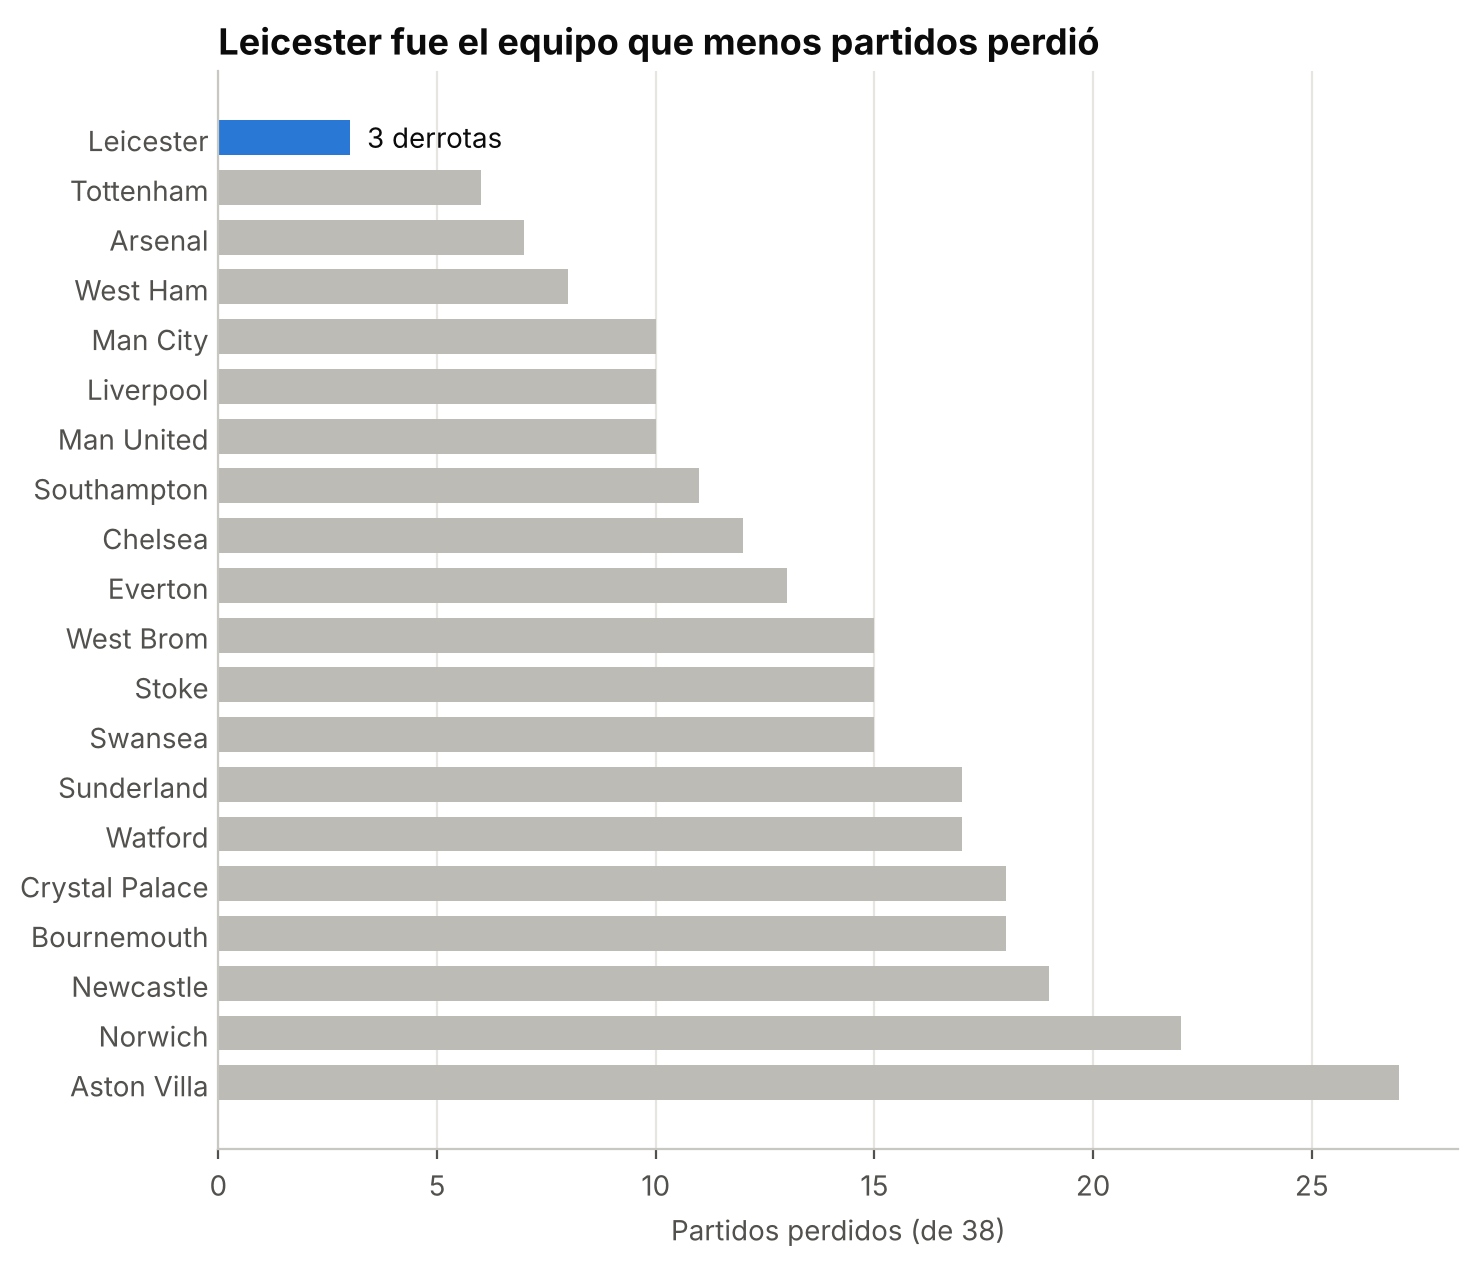

In [22]:
# barh dibuja de abajo hacia arriba: ordenamos de más a menos derrotas para que Leicester quede arriba
losses = table.sort_values("losses", ascending=False)
colors = [HIGHLIGHT if team == TEAM else NEUTRAL for team in losses["team"]]

fig, ax = plt.subplots(figsize=(8, 7))

ax.barh(losses["team"], losses["losses"], color=colors, height=0.7)

leicester_losses = table.loc[table["team"] == TEAM, "losses"].iloc[0]
ax.text(leicester_losses + 0.4, TEAM, f"{leicester_losses} derrotas", va="center", color=TEXT_PRIMARY)

ax.set_title("Leicester fue el equipo que menos partidos perdió")
ax.set_xlabel("Partidos perdidos (de 38)")
ax.grid(axis="x")
ax.set_axisbelow(True)
ax.tick_params(axis="y", length=0)

fig.savefig(IMAGES_DIR / "derrotas_por_equipo.png")
plt.show()

**Segundo hallazgo**

Leicester no fue el equipo más goleador: marcó 68 goles, 3 menos que Manchester City (71) y 1 menos que Tottenham (69). Su campeonato no se explica por la cantidad de goles.

In [23]:
attack_ranking = table.sort_values(by="goals_for", ascending=False)
attack_ranking = attack_ranking[["position", "team", "goals_for"]]

print(attack_ranking.head(10).to_string(index=False))

 position        team  goals_for
        4    Man City         71
        3   Tottenham         69
        1   Leicester         68
        2     Arsenal         65
        7    West Ham         65
        8   Liverpool         63
        6 Southampton         59
       10     Chelsea         59
       11     Everton         59
        5  Man United         49


**Tercer hallazgo**

Leicester no fue la mejor defensa: recibió 36 goles, igual que Arsenal, mientras que Tottenham y Manchester United recibieron 35. Aun así, estuvo entre las cuatro defensas menos goleadas, claramente separado del quinto puesto (Manchester City y Southampton, con 41).

In [24]:
defense_ranking = table.sort_values(by="goals_against")
defense_ranking = defense_ranking[["position", "team", "goals_against"]]

print(defense_ranking.to_string(index=False))

 position           team  goals_against
        3      Tottenham             35
        5     Man United             35
        2        Arsenal             36
        1      Leicester             36
        4       Man City             41
        6    Southampton             41
       14      West Brom             48
        8      Liverpool             50
       13        Watford             50
        7       West Ham             51
       15 Crystal Palace             51
       12        Swansea             52
       10        Chelsea             53
        9          Stoke             55
       11        Everton             55
       17     Sunderland             62
       18      Newcastle             65
       16    Bournemouth             67
       19        Norwich             67
       20    Aston Villa             76


**Conclusión**

Leicester no lideró ni la tabla de goles a favor ni la de goles recibidos, pero estuvo entre los mejores en ambas: fue el tercer ataque (68 goles) y una de las cuatro defensas menos goleadas (36).

El dato más diferencial es la cantidad de derrotas: perdió solo 3 de 38 partidos, la menor cifra de la liga, mientras que los equipos del 2° al 5° puesto perdieron entre 6 y 10. Esto sugiere que la clave no fue dominar una métrica específica, sino sostener un rendimiento alto y parejo durante toda la temporada.

## 5. ¿Fortaleza de local o de visitante?

Agrupamos los partidos de Leicester según si jugó de local o de visitante

In [25]:
venue_stats = leicester.groupby("venue").agg(
    matches=("points", "size"),
    points=("points", "sum"),
    wins=("result", lambda r: count_results(r, "Win")),
    goals_for=("goals_for", "sum"),
    goals_against=("goals_against", "sum")
)

venue_stats = venue_stats.loc[["home", "away"]]

venue_stats

,matches,points,wins,goals_for,goals_against
venue,,,,,
home,19,42,12,35,18
away,19,39,11,33,18


Comparamos los puntos de local y de visitante de todos los equipos para ubicar a Leicester en el contexto de la liga.

In [26]:
venue_points = team_matches.pivot_table(index="team", columns="venue", values="points", aggfunc="sum")

print("Mejores locales:")
print(venue_points["home"].sort_values(ascending=False).head(3).to_string())
print("\nMejores visitantes:")
print(venue_points["away"].sort_values(ascending=False).head(3).to_string())

Mejores locales:
team
Leicester     42
Man United    41
Arsenal       40

Mejores visitantes:
team
Leicester    39
Tottenham    34
Arsenal      31


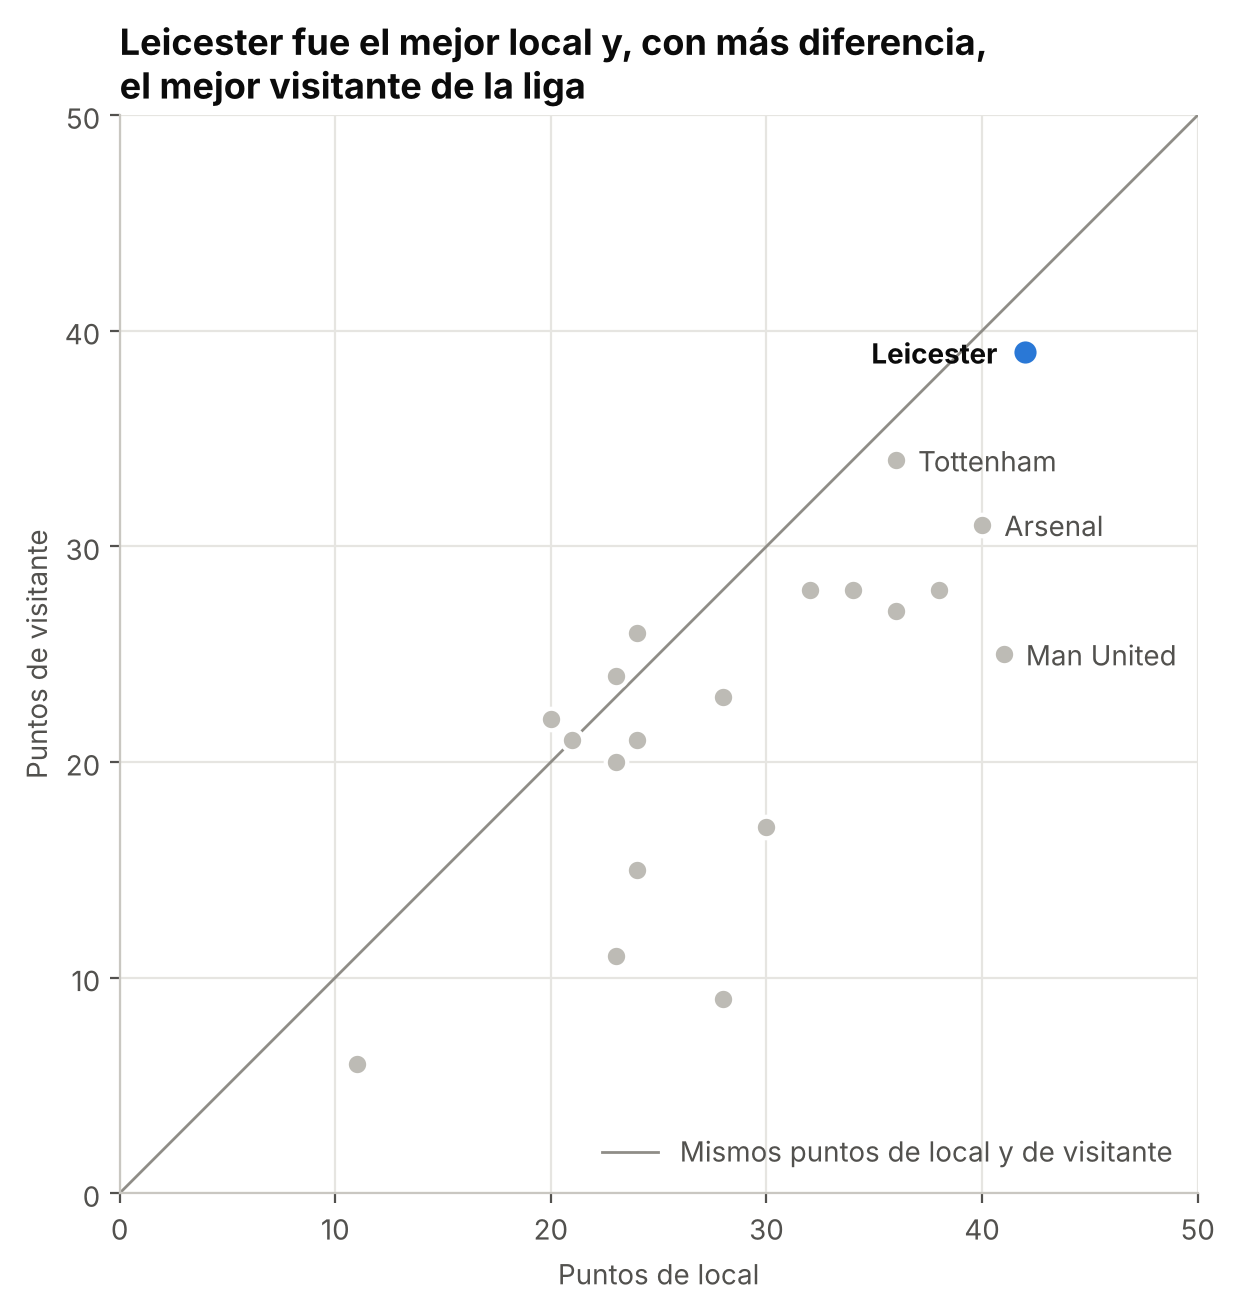

In [27]:
others = venue_points.drop(TEAM)

fig, ax = plt.subplots(figsize=(7, 7))

# Línea de referencia: mismos puntos de local que de visitante
ax.plot([0, 50], [0, 50], color=REFERENCE, linewidth=1, zorder=1,
        label="Mismos puntos de local y de visitante")

ax.scatter(others["home"], others["away"], s=60, color=NEUTRAL, edgecolor="white", linewidth=1.5, zorder=2)
ax.scatter(venue_points.loc[TEAM, "home"], venue_points.loc[TEAM, "away"],
           s=90, color=HIGHLIGHT, edgecolor="white", linewidth=1.5, zorder=3)

labels = {
    TEAM: (-10, -4, "right"),
    "Tottenham": (8, -4, "left"),
    "Arsenal": (8, -4, "left"),
    "Man United": (8, -4, "left")
}
for team, (dx, dy, ha) in labels.items():
    color = TEXT_PRIMARY if team == TEAM else TEXT_SECONDARY
    ax.annotate(team, (venue_points.loc[team, "home"], venue_points.loc[team, "away"]),
                xytext=(dx, dy), textcoords="offset points", ha=ha, color=color,
                fontweight="bold" if team == TEAM else "normal")

ax.set_title("Leicester fue el mejor local y, con más diferencia,\nel mejor visitante de la liga")
ax.set_xlabel("Puntos de local")
ax.set_ylabel("Puntos de visitante")
ax.set_xlim(0, 50)
ax.set_ylim(0, 50)
ax.set_aspect("equal")
ax.legend(loc="lower right", frameon=False, labelcolor=TEXT_SECONDARY)
ax.grid()
ax.set_axisbelow(True)

fig.savefig(IMAGES_DIR / "puntos_local_visitante.png")
plt.show()

Los equipos que están por debajo de la diagonal sumaron más puntos de local que de visitante. Leicester queda cerca de la línea, y es el punto más alto en ambos ejes.

**Conclusión**

Uno de los aspectos más destacados de la temporada 2015/16 fue la consistencia del Leicester City tanto en casa como fuera de ella. El equipo obtuvo 42 puntos como local y 39 como visitante, mostrando un rendimiento prácticamente idéntico en ambos escenarios.

Además, mantuvo el mismo nivel defensivo al recibir únicamente 18 goles tanto en condición de local como de visitante. En ataque también presentó cifras muy similares, con 35 goles anotados en casa y 33 fuera de ella.

En el contexto de la liga, fue el mejor equipo en ambas condiciones, pero la diferencia fue mucho mayor de visitante: sumó 39 puntos fuera de casa, 5 más que Tottenham (34), mientras que de local superó por solo un punto a Manchester United (42 contra 41).

Estos resultados indican que Leicester rindió de forma pareja como local y como visitante, sin depender de jugar en su estadio, y que su campaña como visitante fue una de las que más lo diferenció del resto.

## 6. Efectividad de cara al arco

Totales de goles, tiros y tiros al arco

In [28]:
print("Goles:", leicester["goals_for"].sum())
print("Tiros:", leicester["shots"].sum())
print("Tiros al arco:", leicester["shots_on_target"].sum())

Goles: 68
Tiros: 523
Tiros al arco: 181


Métricas de eficiencia:

- Conversión de tiros: goles / tiros totales.
- Conversión de tiros al arco: goles / tiros al arco.
- Precisión: tiros al arco / tiros totales.
- Tiros por partido.

In [29]:
conversion_rate = (
    leicester["goals_for"].sum()
    / leicester["shots"].sum()
)

print("Conversión de tiros:", round(conversion_rate * 100, 2), "%")


shot_on_target_conversion = (
    leicester["goals_for"].sum()
    / leicester["shots_on_target"].sum()
)

print("Conversión de tiros al arco:", round(shot_on_target_conversion * 100, 2), "%")


accuracy = (
    leicester["shots_on_target"].sum()
    / leicester["shots"].sum()
)

print("Precisión:", round(accuracy * 100, 2), "%")

shots_per_match = leicester["shots"].sum() / len(leicester)
print("Tiros por partido:", round(shots_per_match, 2))

Conversión de tiros: 13.0 %
Conversión de tiros al arco: 37.57 %
Precisión: 34.61 %
Tiros por partido: 13.76


Todavía no podemos afirmar si Leicester fue extremadamente eficiente. ¿13.0 % de tasa de conversión es mucho o poco para la Premier League 2015/16?

Vamos a responderlo comparándolo con sus perseguidores.

In [30]:
efficiency = team_matches.groupby("team").agg(
    goals=("goals_for", "sum"),
    shots=("shots", "sum"),
    shots_on_target=("shots_on_target", "sum")
)

efficiency["conversion_rate"] = (efficiency["goals"] / efficiency["shots"] * 100).round(2)
efficiency["accuracy"] = (efficiency["shots_on_target"] / efficiency["shots"] * 100).round(2)
efficiency["shot_on_target_conversion"] = (efficiency["goals"] / efficiency["shots_on_target"] * 100).round(2)

In [31]:
contenders = [
    "Leicester",
    "Arsenal",
    "Tottenham",
    "Man City",
    "Man United"
]

comparison = efficiency.loc[contenders].reset_index()

comparison

,team,goals,shots,shots_on_target,conversion_rate,accuracy,shot_on_target_conversion
0,Leicester,68,523,181,13.00,34.61,37.57
1,Arsenal,65,572,210,11.36,36.71,30.95
2,Tottenham,69,661,250,10.44,37.82,27.60
3,Man City,71,612,210,11.60,34.31,33.81
4,Man United,49,430,143,11.40,33.26,34.27


Ampliamos la comparación a los 20 equipos de la liga

In [32]:
league_conversion = efficiency["goals"].sum() / efficiency["shots"].sum()

print("Conversión promedio de la liga:", round(league_conversion * 100, 2), "%")
print()
print(efficiency["conversion_rate"].sort_values(ascending=False).head(5).to_string())

Conversión promedio de la liga: 10.51 %

team
Leicester     13.00
Everton       11.99
West Ham      11.69
Man City      11.60
Man United    11.40


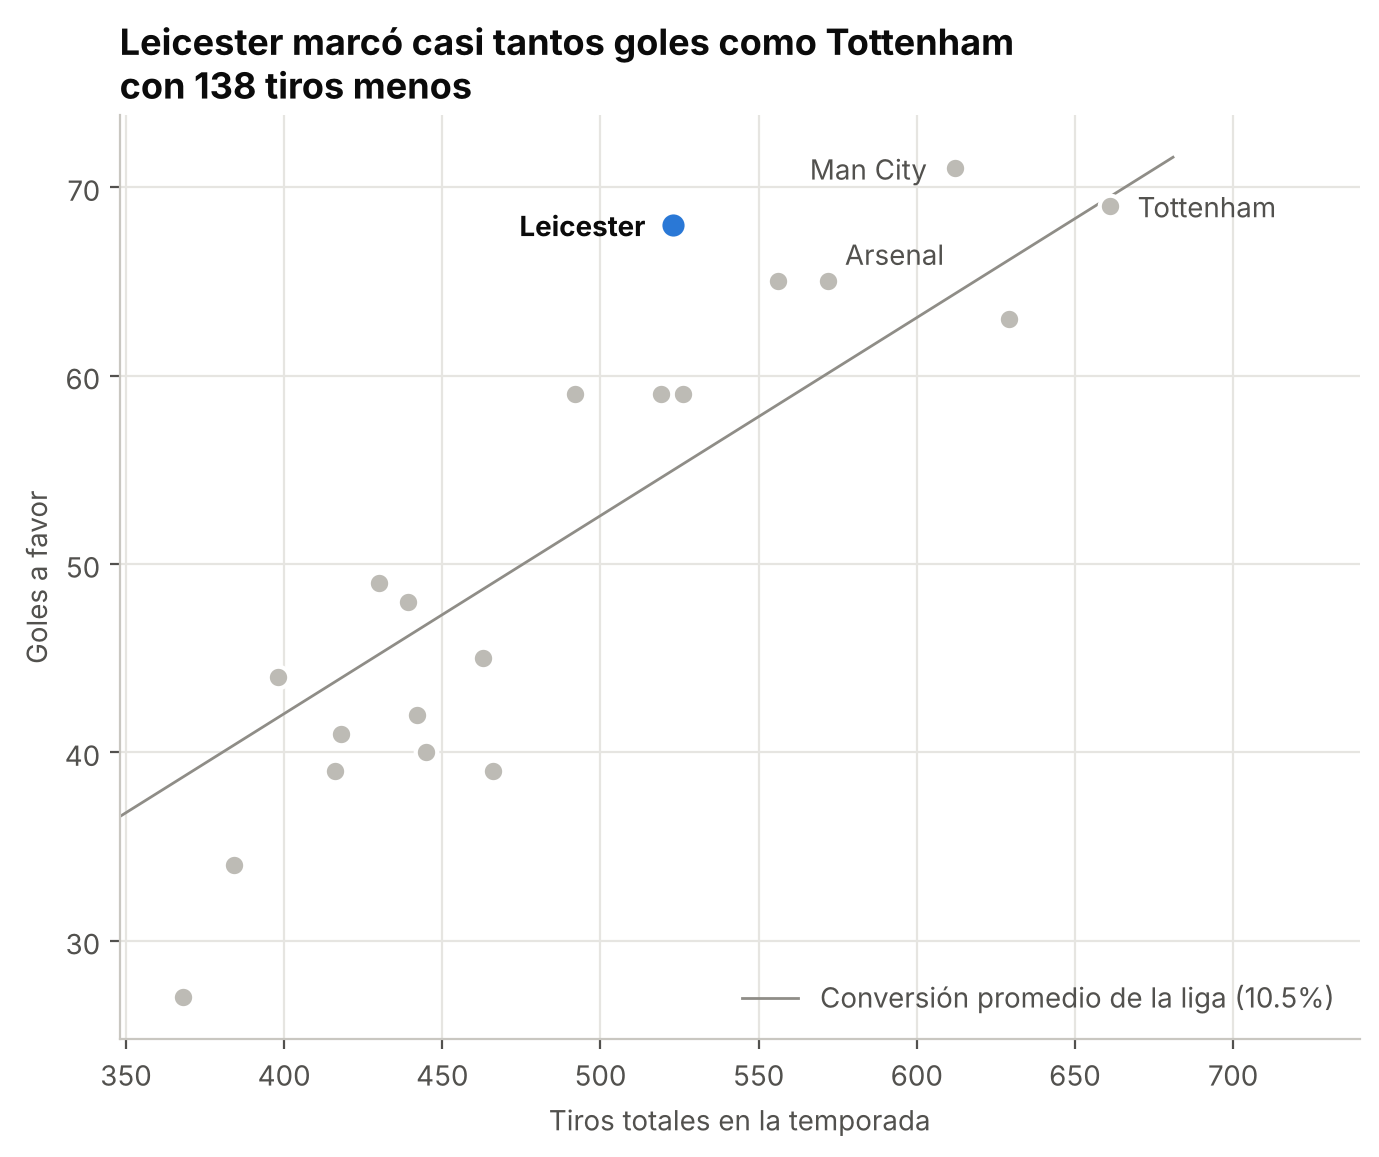

In [33]:
others = efficiency.drop(TEAM)

fig, ax = plt.subplots(figsize=(8, 6))

# Línea de referencia: goles que haría un equipo con la conversión promedio de la liga
shots_range = np.array([efficiency["shots"].min() - 20, efficiency["shots"].max() + 20])
ax.plot(shots_range, shots_range * league_conversion, color=REFERENCE, linewidth=1, zorder=1,
        label=f"Conversión promedio de la liga ({league_conversion:.1%})")

ax.scatter(others["shots"], others["goals"], s=60, color=NEUTRAL, edgecolor="white", linewidth=1.5, zorder=2)
ax.scatter(efficiency.loc[TEAM, "shots"], efficiency.loc[TEAM, "goals"],
           s=90, color=HIGHLIGHT, edgecolor="white", linewidth=1.5, zorder=3)

labels = {
    TEAM: (-10, -4, "right"),
    "Tottenham": (10, -4, "left"),
    "Man City": (-10, -4, "right"),
    "Arsenal": (6, 6, "left")
}
for team, (dx, dy, ha) in labels.items():
    color = TEXT_PRIMARY if team == TEAM else TEXT_SECONDARY
    ax.annotate(team, (efficiency.loc[team, "shots"], efficiency.loc[team, "goals"]),
                xytext=(dx, dy), textcoords="offset points", ha=ha, color=color,
                fontweight="bold" if team == TEAM else "normal")

ax.set_title("Leicester marcó casi tantos goles como Tottenham\ncon 138 tiros menos")
ax.set_xlabel("Tiros totales en la temporada")
ax.set_ylabel("Goles a favor")
ax.set_xlim(shots_range[0], 740)
ax.legend(loc="lower right", frameon=False, labelcolor=TEXT_SECONDARY)
ax.grid()
ax.set_axisbelow(True)

fig.savefig(IMAGES_DIR / "tiros_vs_goles.png")
plt.show()

Los equipos por encima de la línea convirtieron más goles de los que les correspondería con la conversión promedio de la liga. Leicester es el que más se separa hacia arriba. El partido con la inconsistencia de tiros (Aston Villa vs. West Ham) afecta a uno solo de los 38 partidos de esos dos equipos y no cambia la lectura del gráfico.

**Conclusión**

Leicester no fue el equipo que más remató, pero sí el más eficiente de la liga para convertir sus tiros en goles.

Leicester convirtió el 13% de sus tiros en goles, la mejor tasa de toda la liga (el promedio fue 10.51%). Además, el 37.57% de sus tiros al arco terminaron en gol, superando a los otros cuatro equipos.

La comparación con Tottenham resulta especialmente interesante. Mientras que Tottenham registró 661 tiros y 250 tiros al arco, las cifras más altas entre los equipos analizados, Leicester produjo solo 523 tiros y 181 tiros al arco. Sin embargo, ambos equipos terminaron la temporada con una cantidad de goles muy similar (69 para Tottenham y 68 para Leicester). Es decir, Leicester necesitó muchas menos oportunidades para alcanzar prácticamente la misma producción ofensiva.

Estos resultados sugieren que el éxito de Leicester no se basó en un mayor volumen de ataques, sino en aprovechar mejor sus oportunidades. Conviene tomarlo con cautela: el dataset no mide la calidad de las ocasiones (xG), por lo que una conversión alta en una sola temporada puede reflejar tanto calidad de definición como variabilidad.

## 7. ¿Superó las expectativas de las casas de apuestas?

Primero creamos una columna que indique si Leicester era favorito según Bet365: es favorito cuando su cuota de victoria es menor que la de su rival.

In [34]:
leicester["favorite"] = leicester["odds"] < leicester["opponent_odds"]

leicester["favorite"].value_counts()

favorite
True     21
False    17
Name: count, dtype: int64

Calculamos victorias y puntos siendo no favorito

In [35]:
underdog = leicester[~leicester["favorite"]]

print("Victorias como no favorito:", count_results(underdog["result"], "Win"))
print("Puntos como no favorito:", underdog["points"].sum())

Victorias como no favorito: 7
Puntos como no favorito: 28


Que Leicester no fuera favorito en 17 partidos no alcanza para decir que superó las expectativas: hay que comparar lo que el mercado esperaba con lo que realmente pasó.

Comparamos los puntos esperados según las cuotas con los puntos obtenidos, para los 20 equipos.

In [36]:
expected = team_matches.groupby("team").agg(
    points=("points", "sum"),
    expected_points=("expected_points", "sum")
)
expected["difference"] = expected["points"] - expected["expected_points"]
expected = expected.round(1).sort_values("difference", ascending=False)

print(expected.to_string())

                points  expected_points  difference
team                                               
Leicester           81             53.3        27.7
West Ham            62             46.6        15.4
Stoke               51             44.5         6.5
Tottenham           70             65.0         5.0
Southampton         63             58.0         5.0
West Brom           43             38.9         4.1
Watford             45             42.0         3.0
Sunderland          39             37.1         1.9
Swansea             47             45.4         1.6
Man United          66             66.0         0.0
Arsenal             71             74.0        -3.0
Newcastle           37             40.6        -3.6
Liverpool           60             64.1        -4.1
Crystal Palace      42             46.1        -4.1
Bournemouth         42             46.9        -4.9
Everton             47             53.7        -6.7
Norwich             34             41.9        -7.9
Man City    

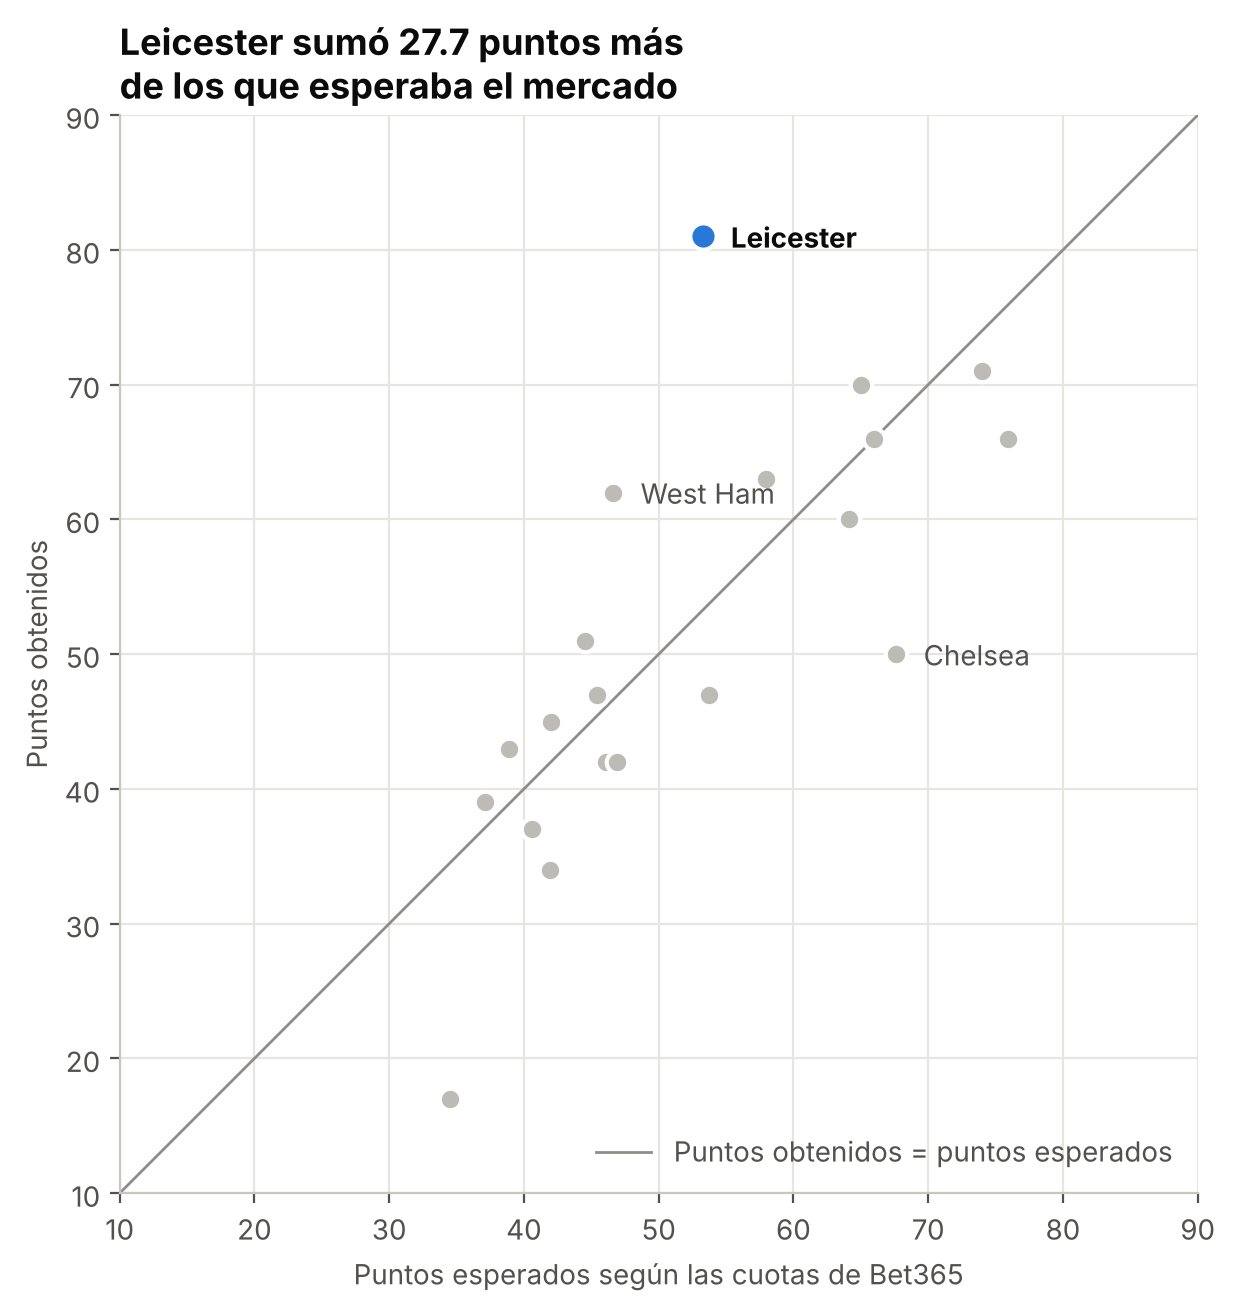

In [37]:
others = expected.drop(TEAM)
leicester_difference = expected.loc[TEAM, "difference"]

fig, ax = plt.subplots(figsize=(7, 7))

# Línea de referencia: el equipo sumó exactamente lo que esperaba el mercado
ax.plot([10, 90], [10, 90], color=REFERENCE, linewidth=1, zorder=1,
        label="Puntos obtenidos = puntos esperados")

ax.scatter(others["expected_points"], others["points"], s=60, color=NEUTRAL, edgecolor="white", linewidth=1.5, zorder=2)
ax.scatter(expected.loc[TEAM, "expected_points"], expected.loc[TEAM, "points"],
           s=90, color=HIGHLIGHT, edgecolor="white", linewidth=1.5, zorder=3)

labels = {
    TEAM: (10, -4, "left"),
    "West Ham": (10, -4, "left"),
    "Chelsea": (10, -4, "left")
}
for team, (dx, dy, ha) in labels.items():
    color = TEXT_PRIMARY if team == TEAM else TEXT_SECONDARY
    ax.annotate(team, (expected.loc[team, "expected_points"], expected.loc[team, "points"]),
                xytext=(dx, dy), textcoords="offset points", ha=ha, color=color,
                fontweight="bold" if team == TEAM else "normal")

ax.set_title(f"Leicester sumó {leicester_difference} puntos más\nde los que esperaba el mercado")
ax.set_xlabel("Puntos esperados según las cuotas de Bet365")
ax.set_ylabel("Puntos obtenidos")
ax.set_xlim(10, 90)
ax.set_ylim(10, 90)
ax.set_aspect("equal")
ax.legend(loc="lower right", frameon=False, labelcolor=TEXT_SECONDARY)
ax.grid()
ax.set_axisbelow(True)

fig.savefig(IMAGES_DIR / "puntos_esperados_vs_reales.png")
plt.show()

Los equipos por encima de la diagonal sumaron más puntos de los que esperaba el mercado y los que están por debajo, menos. Leicester es el que más se separa de la línea.

¿Cambiaron las expectativas a lo largo de la temporada? Comparamos la primera mitad (partidos 1 a 19 de Leicester) con la segunda (partidos 20 a 38).

In [38]:
leicester["half"] = np.where(leicester["match_number"] <= 19, "Primera mitad", "Segunda mitad")

by_half = leicester.groupby("half").agg(
    matches=("points", "size"),
    favorite_matches=("favorite", "sum"),
    avg_win_probability=("win_probability", "mean"),
    expected_points=("expected_points", "sum"),
    points=("points", "sum")
)
by_half["difference"] = by_half["points"] - by_half["expected_points"]

by_half.round(2)

,matches,favorite_matches,avg_win_probability,expected_points,points,difference
half,,,,,,
Primera mitad,19,7,0.34,24.44,39,14.56
Segunda mitad,19,14,0.42,28.82,42,13.18


**Conclusión**

Leicester no fue favorito en 17 de sus 38 partidos y en esos encuentros sumó 28 puntos y 7 victorias, el 34.6% de sus puntos totales.

La comparación con los puntos esperados permite medir cuánto superó las expectativas. Según las cuotas de Bet365, el mercado esperaba que Leicester sumara 53.3 puntos y terminó con 81: una diferencia de 27.7 puntos, la mayor de la liga. El segundo equipo que más superó las expectativas fue West Ham, con 15.4 puntos de diferencia.

El mercado ajustó sus expectativas a lo largo de la temporada. En la primera mitad, Leicester fue favorito en 7 de 19 partidos y su probabilidad promedio de ganar era del 34%. En la segunda mitad fue favorito en 14 de 19 partidos y esa probabilidad subió al 42%. Aun así, superó lo esperado en las dos mitades: sumó 39 puntos contra 24.4 esperados en la primera y 42 contra 28.8 en la segunda.

Esto indica que Leicester superó las expectativas del mercado durante toda la temporada, incluso cuando las casas de apuestas ya lo consideraban candidato.

## 8. Evolución a lo largo de la temporada

Calculamos los puntos acumulados de Leicester y de sus dos principales perseguidores, Arsenal y Tottenham, partido a partido. Se usa el número de partido de cada equipo (y no la fecha) porque algunos partidos se jugaron en fechas distintas por postergaciones.

In [39]:
rivals = ["Arsenal", "Tottenham"]

race = team_matches[team_matches["team"].isin([TEAM] + rivals)].copy()
race["cumulative_points"] = race.groupby("team")["points"].cumsum()

race_table = race.pivot(index="match_number", columns="team", values="cumulative_points")
race_table["leicester_lead"] = race_table[TEAM] - race_table[rivals].max(axis=1)

print("Partidos en los que Leicester tenía menos puntos que alguno de sus rivales:")
print(race_table[race_table["leicester_lead"] < 0].index.tolist())
print()
print(race_table.loc[[10, 19, 29, 38]].to_string())

Partidos en los que Leicester tenía menos puntos que alguno de sus rivales:
[7, 8, 9, 10, 11, 12, 20]

team          Arsenal  Leicester  Tottenham  leicester_lead
match_number                                               
10                 22         19         17              -3
19                 39         39         35               0
29                 52         60         55               5
38                 71         81         70              10


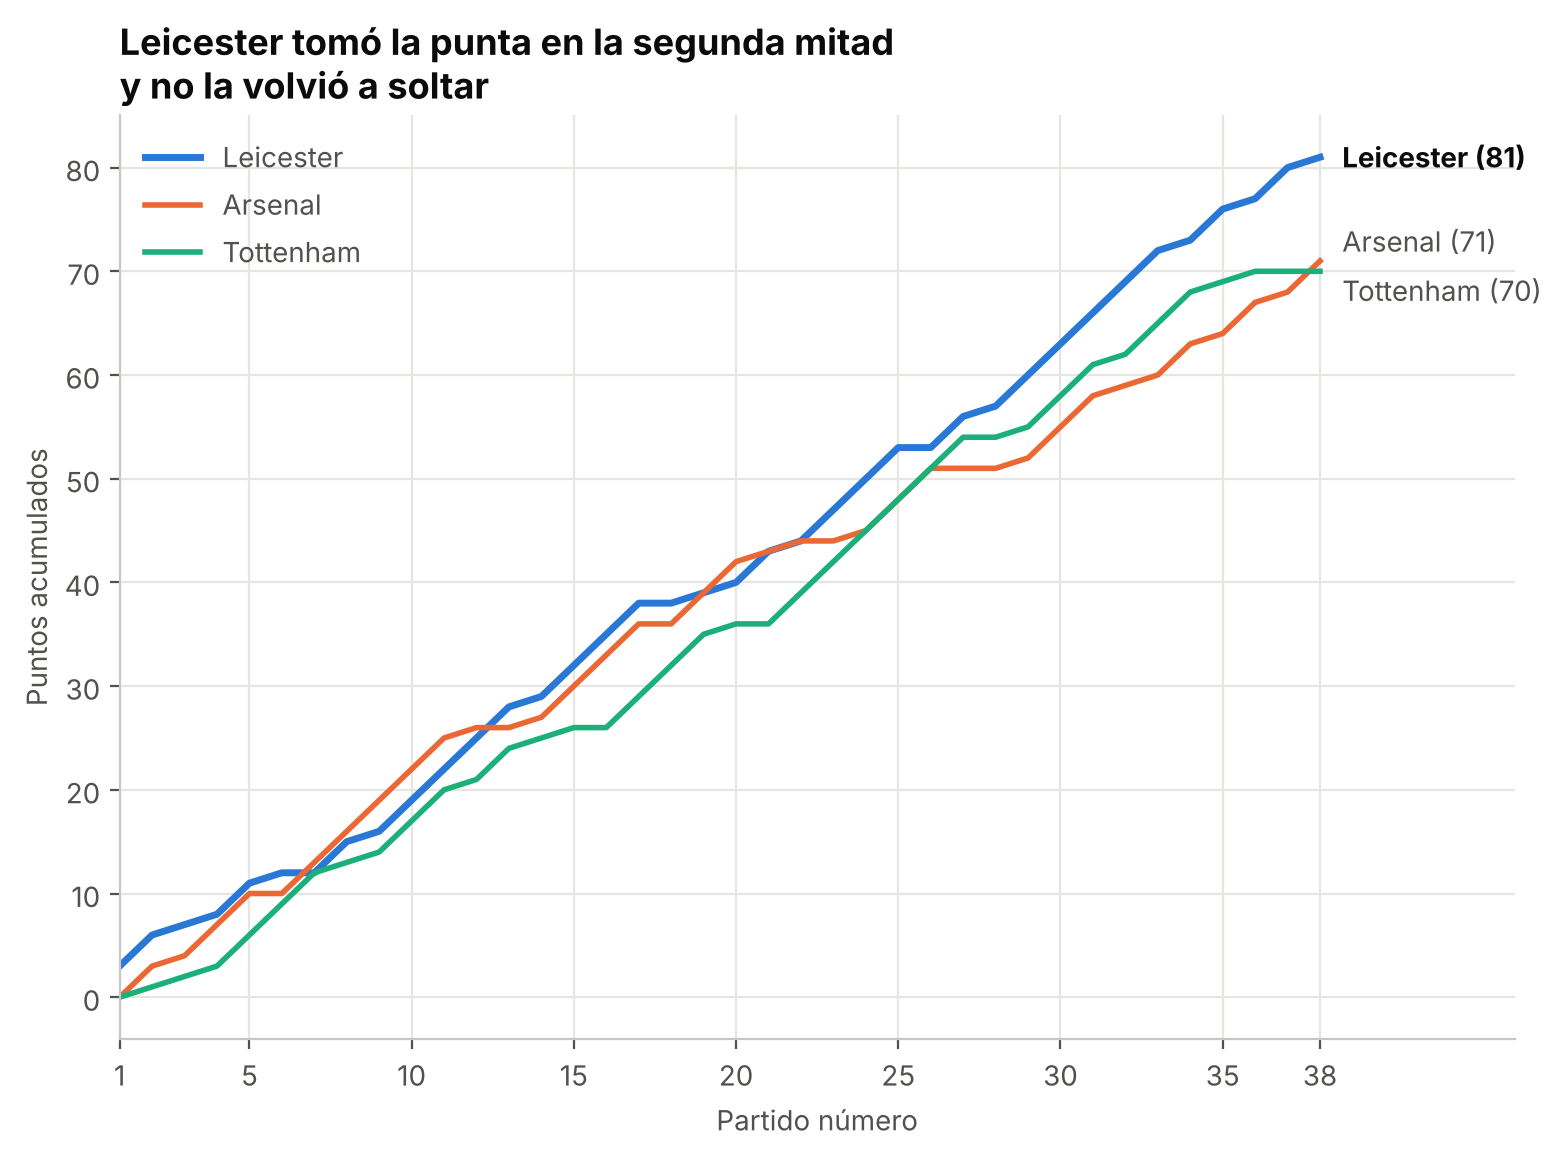

In [40]:
race_colors = {TEAM: HIGHLIGHT, "Arsenal": "#eb6834", "Tottenham": "#1baf7a"}
# Desplazamiento vertical de las etiquetas finales (Arsenal y Tottenham terminan casi empatados)
label_offsets = {TEAM: 0, "Arsenal": 7, "Tottenham": -7}

fig, ax = plt.subplots(figsize=(9, 6))

for team, color in race_colors.items():
    ax.plot(race_table.index, race_table[team], color=color, linewidth=2.5 if team == TEAM else 2, label=team)
    ax.annotate(f"{team} ({race_table.loc[38, team]})", (38, race_table.loc[38, team]),
                xytext=(8, label_offsets[team]), textcoords="offset points", va="center",
                color=TEXT_PRIMARY if team == TEAM else TEXT_SECONDARY,
                fontweight="bold" if team == TEAM else "normal")

ax.set_title("Leicester tomó la punta en la segunda mitad\ny no la volvió a soltar")
ax.set_xlabel("Partido número")
ax.set_ylabel("Puntos acumulados")
ax.set_xlim(1, 44)
ax.set_xticks([1, 5, 10, 15, 20, 25, 30, 35, 38])
ax.legend(loc="upper left", frameon=False, labelcolor=TEXT_SECONDARY)
ax.grid()
ax.set_axisbelow(True)

fig.savefig(IMAGES_DIR / "puntos_acumulados.png")
plt.show()

**Conclusión**

Leicester tuvo menos puntos que Arsenal o Tottenham después de sus partidos 7 a 12 y del partido 20. Desde el partido 21 hasta el final fue siempre el que más puntos sumaba de los tres, y terminó con 10 puntos de ventaja sobre Arsenal.

El título no se explica por un arranque excepcional: se construyó con un rendimiento sostenido que le permitió tomar la punta en la segunda mitad de la temporada y mantenerla hasta el final.

## 9. Conclusión final

El objetivo de este proyecto fue entender cómo Leicester City ganó la Premier League 2015/16. El análisis identifica varios factores que, en conjunto, explican su campeonato.

En primer lugar, la regularidad. Leicester terminó con 81 puntos (23 victorias, 12 empates y 3 derrotas) y fue el equipo que menos partidos perdió en la liga. Los equipos del 2° al 5° puesto perdieron entre 6 y 10.

En segundo lugar, el equilibrio. No fue el equipo más goleador ni el que menos goles recibió, pero estuvo entre los mejores en ambas facetas: fue el tercer ataque de la liga (68 goles) y una de las cuatro defensas menos goleadas (36).

En tercer lugar, un rendimiento parejo como local y como visitante: sumó 42 puntos en casa y 39 fuera, y recibió 18 goles en cada condición. Fue el mejor equipo de la liga en ambas condiciones, con una diferencia mayor como visitante (5 puntos sobre Tottenham) que como local (1 punto sobre Manchester United).

En cuarto lugar, la eficiencia ofensiva. Tuvo la mejor tasa de conversión de la liga (13% de sus tiros terminaron en gol, contra un promedio de 10.51%) y, con 138 tiros menos que Tottenham, marcó solo un gol menos. Como el dataset no incluye la calidad de las ocasiones, no es posible determinar cuánto de esa eficiencia se debe a la definición y cuánto a la variabilidad.

En quinto lugar, superó las expectativas del mercado durante toda la temporada. Según las cuotas de Bet365, se esperaba que sumara 53.3 puntos y terminó con 81, la mayor diferencia de la liga. Las casas de apuestas ajustaron sus expectativas en la segunda mitad (pasó de ser favorito en 7 de 19 partidos a serlo en 14 de 19), pero Leicester siguió sumando más de lo esperado.

Por último, la evolución de la temporada muestra que el título se construyó con regularidad: Leicester tomó la punta a partir de su partido 21 y no la volvió a perder.

En conclusión, los datos indican que Leicester City no ganó la Premier League 2015/16 por dominar una estadística específica, sino por combinar regularidad, equilibrio y eficiencia, con un rendimiento que superó de forma sostenida lo que esperaba el mercado.